# EDA N2 và N4 cho phân loại bình luận độc hại

Notebook tính lại thống kê từ parquet N2, gói huấn luyện N4 và artifact augmentation. Nhãn là 0 = CLEAN, 1 = TOXIC. N4 train có thêm augmentation; không diễn giải tỷ lệ TOXIC train như tỷ lệ toàn bộ N4. Notebook G0 được giữ nguyên.

`src/eda/eda_utils.py` đọc JSONL và ánh xạ ba nhãn, trong khi dữ liệu này là Parquet nhị phân. Vì vậy notebook không gọi các helper không tương thích; các phép tính cần thiết được viết trực tiếp tại đây.


In [1]:
from pathlib import Path
import re
import unicodedata
from collections import Counter
from difflib import SequenceMatcher

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

roots = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p.resolve() for p in roots if (p / 'data/processed/binary_n2_v1').is_dir() and (p / 'data/processed/binary_n4_training_v1').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Không tìm thấy repo chứa các parquet N2 và N4')
LABEL_NAMES = {0: 'CLEAN', 1: 'TOXIC'}
SPLITS = ('train', 'val', 'test')
plt.rcParams['figure.dpi'] = 110

def load_splits(directory):
    return {split: pd.read_parquet(directory / f'{split}.parquet') for split in SPLITS}

datasets = {'N2': load_splits(ROOT / 'data/processed/binary_n2_v1'), 'N4': load_splits(ROOT / 'data/processed/binary_n4_training_v1')}
augmentation = pd.read_parquet(ROOT / 'data/processed/binary_n4_v1/augmentation.parquet')
print(f'N2: {sum(map(len, datasets["N2"].values())):,}; N4: {sum(map(len, datasets["N4"].values())):,}; augmentation: {len(augmentation):,}')


N2: 40,327; N4: 46,002; augmentation: 5,675


## Kích thước và phân bố nhãn

Bảng tách CLEAN/TOXIC count và rate theo dataset, split; bảng so sánh cũng ghi kích thước từng split và tổng.


count          rate_pct       
label                  CLEAN    TOXIC    CLEAN  TOXIC
dataset split n                                      
N2      test  6048    5084.0    964.0    84.06  15.94
        train 28231  23734.0   4497.0    84.07  15.93
        val   6048    5084.0    964.0    84.06  15.94
N4      test  6048    5084.0    964.0    84.06  15.94
        train 33906  23734.0  10172.0    70.00  30.00
        val   6048    5084.0    964.0    84.06  15.94

,train_n,train_CLEAN,train_TOXIC,train_TOXIC_pct,val_n,val_CLEAN,val_TOXIC,val_TOXIC_pct,test_n,test_CLEAN,test_TOXIC,test_TOXIC_pct,total_n
dataset,,,,,,,,,,,,,
N2,28231,23734,4497,15.93,6048,5084,964,15.94,6048,5084,964,15.94,40327
N4,33906,23734,10172,30.00,6048,5084,964,15.94,6048,5084,964,15.94,46002


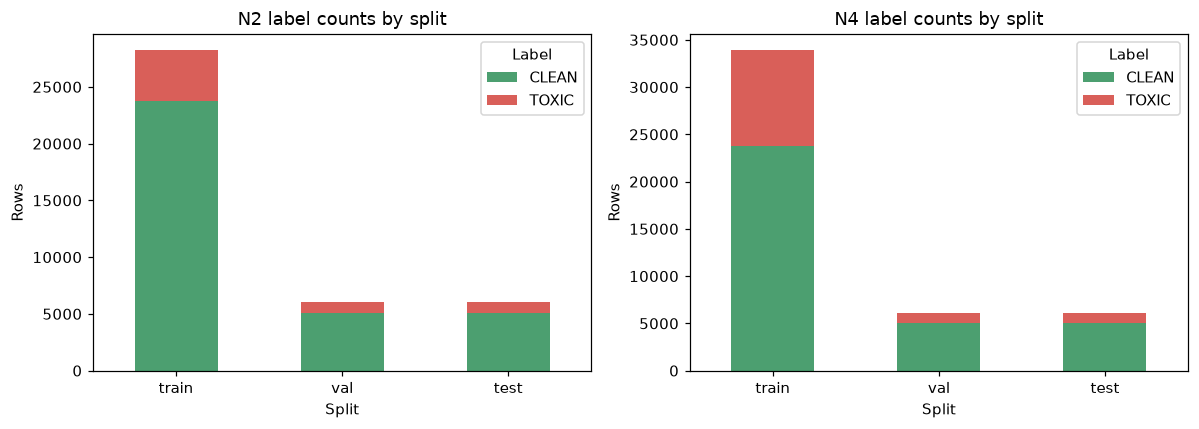

N4 thêm 5,675 mẫu train, tất cả là TOXIC. CLEAN giữ nguyên 23,734 mẫu; TOXIC tăng từ 4,497 lên 10,172. Tỷ lệ TOXIC train tăng từ 15.93% lên 30.00%.

In [2]:
label_rows = []
for name, splits in datasets.items():
    for split, df in splits.items():
        counts = df['label'].value_counts()
        for label, label_name in LABEL_NAMES.items():
            count = int(counts.get(label, 0))
            label_rows.append({'dataset': name, 'split': split, 'n': len(df), 'label': label_name, 'count': count, 'rate_pct': 100 * count / len(df)})
label_table = pd.DataFrame(label_rows)
display(label_table.pivot(index=['dataset', 'split', 'n'], columns='label', values=['count', 'rate_pct']).round(2))
comparison_rows = []
for name, splits in datasets.items():
    row = {'dataset': name}
    for split, df in splits.items():
        counts = df['label'].value_counts()
        row.update({f'{split}_n': len(df), f'{split}_CLEAN': int(counts.get(0, 0)), f'{split}_TOXIC': int(counts.get(1, 0)), f'{split}_TOXIC_pct': 100 * counts.get(1, 0) / len(df)})
    row['total_n'] = sum(map(len, splits.values()))
    comparison_rows.append(row)
comparison = pd.DataFrame(comparison_rows).set_index('dataset')
display(comparison.round(2))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, _) in zip(axes, datasets.items()):
    counts = label_table[label_table['dataset'].eq(name)].pivot(index='split', columns='label', values='count').reindex(SPLITS)
    counts[['CLEAN', 'TOXIC']].plot(kind='bar', stacked=True, color=['#4c9f70', '#d95f59'], ax=ax)
    ax.set_title(f'{name} label counts by split'); ax.set_xlabel('Split'); ax.set_ylabel('Rows'); ax.tick_params(axis='x', rotation=0)
    ax.legend(title='Label')
fig.tight_layout(); plt.show()
train_rates = {name: splits['train']['label'].eq(1).mean() * 100 for name, splits in datasets.items()}
n2_train_counts = datasets['N2']['train']['label'].value_counts()
n4_train_counts = datasets['N4']['train']['label'].value_counts()
display(Markdown(f"N4 thêm {len(datasets['N4']['train']) - len(datasets['N2']['train']):,} mẫu train, tất cả là TOXIC. CLEAN giữ nguyên {int(n2_train_counts.get(0, 0)):,} mẫu; TOXIC tăng từ {int(n2_train_counts.get(1, 0)):,} lên {int(n4_train_counts.get(1, 0)):,}. Tỷ lệ TOXIC train tăng từ {train_rates['N2']:.2f}% lên {train_rates['N4']:.2f}%."))


## Độ dài theo nhãn

Word count dùng `str.split()`; character count là độ dài chuỗi Python. Bảng thống kê min, các phân vị đến p99 và max theo dataset, split, nhãn. Biểu đồ cho train theo nhãn và cắt phần hiển thị tại p99.


,dataset,split,label,measure,n,mean,p00,p25,p50,p75,p90,p95,p99,p100
0,N2,test,CLEAN,word_count,5084,15.58,1.0,6.0,10.0,17.00,32.0,48.00,90.17,1417.0
1,N2,test,CLEAN,char_count,5084,67.04,1.0,23.0,40.0,74.00,140.0,208.85,397.68,7712.0
2,N2,test,TOXIC,word_count,964,19.62,1.0,7.0,13.0,23.00,43.0,59.00,94.11,243.0
3,N2,test,TOXIC,char_count,964,82.60,2.0,28.0,54.0,100.00,184.0,256.25,403.55,1055.0
4,N2,train,CLEAN,word_count,23734,15.60,1.0,6.0,10.0,17.00,33.0,48.00,92.00,1701.0
5,N2,train,CLEAN,char_count,23734,67.82,1.0,23.0,40.0,73.00,141.0,212.00,408.67,20816.0
6,N2,train,TOXIC,word_count,4497,19.62,1.0,7.0,13.0,25.00,42.0,59.00,98.00,265.0
7,N2,train,TOXIC,char_count,4497,83.03,2.0,29.0,54.0,105.00,183.0,253.00,423.24,1133.0
8,N2,val,CLEAN,word_count,5084,15.77,1.0,6.0,10.0,18.00,34.0,48.00,91.17,411.0
9,N2,val,CLEAN,char_count,5084,67.29,1.0,22.0,40.0,76.00,146.0,209.00,412.34,1762.0


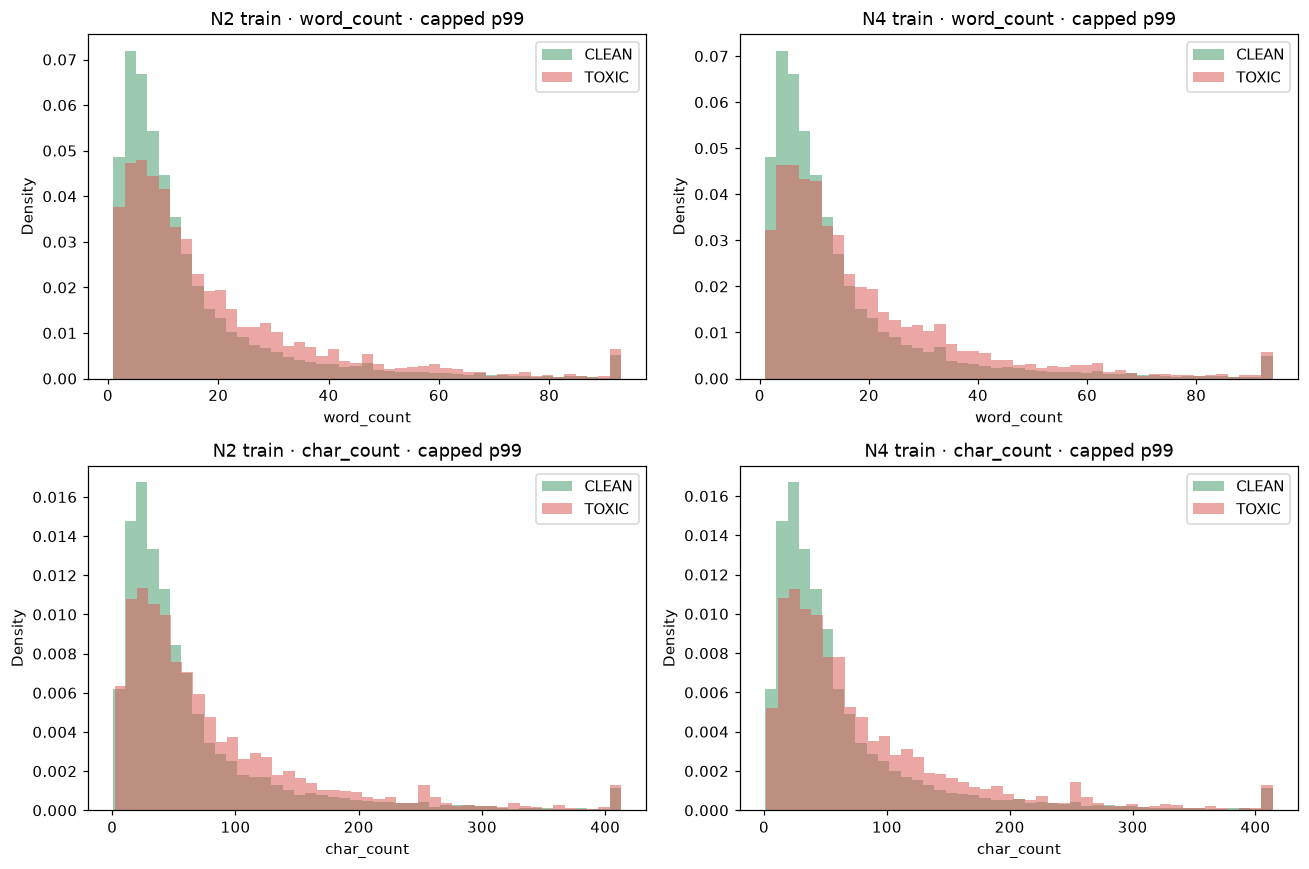

In [3]:
length_frames = []
for name, splits in datasets.items():
    for split, df in splits.items():
        part = df[['text', 'label']].copy(); part['dataset'] = name; part['split'] = split
        part['word_count'] = part['text'].map(lambda text: len(text.split())); part['char_count'] = part['text'].str.len()
        length_frames.append(part)
length_data = pd.concat(length_frames, ignore_index=True)
qs = [0, .25, .5, .75, .9, .95, .99, 1]
rows = []
for (name, split, label), group in length_data.groupby(['dataset', 'split', 'label']):
    for measure in ('word_count', 'char_count'):
        vals = group[measure]; row = {'dataset': name, 'split': split, 'label': LABEL_NAMES[int(label)], 'measure': measure, 'n': len(vals), 'mean': vals.mean()}
        row.update({f'p{int(q * 100):02d}': vals.quantile(q) for q in qs}); rows.append(row)
length_summary = pd.DataFrame(rows); display(length_summary.round(2))
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (name, measure) in zip(axes.flat, [(d, m) for m in ('word_count', 'char_count') for d in datasets]):
    subset = length_data[(length_data['dataset'] == name) & (length_data['split'] == 'train')]; cap = subset[measure].quantile(.99)
    for label, color in ((0, '#4c9f70'), (1, '#d95f59')):
        ax.hist(subset.loc[subset['label'].eq(label), measure].clip(upper=cap), bins=45, alpha=.55, density=True, color=color, label=LABEL_NAMES[label])
    ax.set_title(f'{name} train · {measure} · capped p99'); ax.set_xlabel(measure); ax.set_ylabel('Density'); ax.legend()
fig.tight_layout(); plt.show()


## Từ vựng train theo nhãn

Token được tách whitespace và casefold. Vocabulary size và 15 từ phổ biến nhất được tính riêng cho CLEAN/TOXIC; chart hiển thị 10 từ đứng đầu. Đây là thống kê token bề mặt.


,dataset,label,vocabulary_size,token_count
0,N2,CLEAN,23690,370193
1,N2,TOXIC,9946,88215
2,N4,CLEAN,23690,370193
3,N4,TOXIC,11688,203532


token                                                  ...  \
rank             1   2    3      4    5    6    7    8      9    10  ...   
dataset label                                                        ...   
N2      CLEAN    có  là  thì  không  cho   mà   và  của  người  này  ...   
        TOXIC    là  có  thì    con   mà  cho  cái   nó  không  này  ...   
N4      CLEAN    có  là  thì  không  cho   mà   và  của  người  này  ...   
        TOXIC    là  có  thì    con   mà   nó  cho  cái  không  này  ...   

              count                                                        
rank             6     7     8     9     10    11    12    13    14    15  
dataset label                                                              
N2      CLEAN  2434  2371  2285  2244  2182  2123  1964  1903  1845  1797  
        TOXIC   697   696   693   639   614   606   585   507   505   500  
N4      CLEAN  2434  2371  2285  2244  2182  2123  1964  1903  1845  1797  
        TOXIC  1646  1591  1541  1381  1351  1325  1313  1182  1152  1134  

[4 rows x 30 columns]

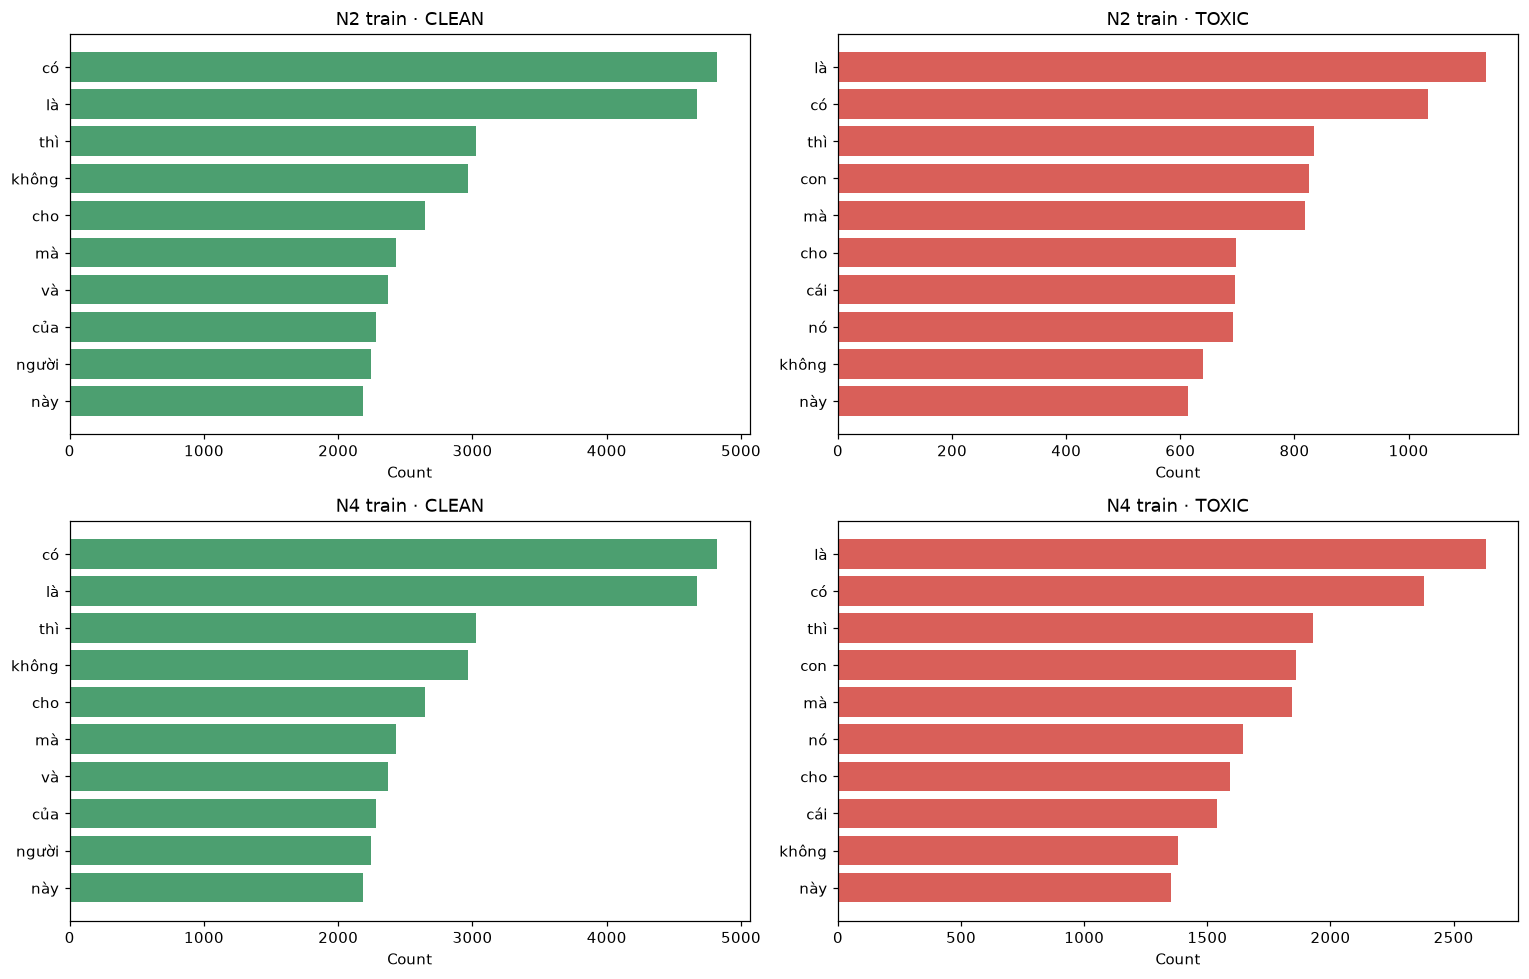

In [4]:
def token_counts(frame):
    result = Counter()
    for text in frame['text']:
        result.update(token.casefold() for token in text.split() if token)
    return result
vocab_rows = []; term_rows = []
for name, splits in datasets.items():
    for label, label_name in LABEL_NAMES.items():
        counts = token_counts(splits['train'].loc[splits['train']['label'].eq(label)])
        vocab_rows.append({'dataset': name, 'label': label_name, 'vocabulary_size': len(counts), 'token_count': sum(counts.values())})
        term_rows.extend({'dataset': name, 'label': label_name, 'rank': rank, 'token': token, 'count': count} for rank, (token, count) in enumerate(counts.most_common(15), 1))
vocabulary_table = pd.DataFrame(vocab_rows); top_terms = pd.DataFrame(term_rows)
display(vocabulary_table); display(top_terms.pivot(index=['dataset', 'label'], columns='rank', values=['token', 'count']))
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (name, label, color) in zip(axes.flat, [(d, l, c) for d in datasets for l, c in ((0, '#4c9f70'), (1, '#d95f59'))]):
    top = top_terms[(top_terms['dataset'] == name) & (top_terms['label'] == LABEL_NAMES[label])].head(10).sort_values('count')
    ax.barh(top['token'], top['count'], color=color); ax.set_title(f'{name} train · {LABEL_NAMES[label]}'); ax.set_xlabel('Count')
fig.tight_layout(); plt.show()


## Null, blank, duplicates và overlap giữa split

Đếm null/blank trên các trường có trong từng schema, bản ghi trùng toàn hàng và text trùng exact. `parent_id` null ở các dòng gốc N4 train là có chủ đích; kiểm tra parent chỉ áp dụng cho dòng augmentation. Các cột augmentation không có trong validation/test theo schema. Khóa chuẩn hóa là NFKC + casefold + xóa ký tự ngoài `\w`; đây chỉ là một dạng trùng khóa, không phải dò near-duplicate tổng quát. Overlap pairwise là số text/key phân biệt chung giữa hai split.


In [5]:
def normalized_key(text):
    return re.sub(r'[^\w]+', '', unicodedata.normalize('NFKC', text).casefold())
def texts(df):
    return [value for value in df['text'] if isinstance(value, str)]
field_rows = []; duplicate_rows = []; overlap_rows = []; schema_rows = []
for name, splits in datasets.items():
    combined = pd.concat(list(splits.values()), ignore_index=True, sort=False)
    for split, df in splits.items():
        for col in df.columns:
            series = df[col]
            field_rows.append({'dataset': name, 'split': split, 'field': col, 'null': int(series.isna().sum()), 'blank_string': int(series.map(lambda v: isinstance(v, str) and not v.strip()).sum())})
        required = {'id', 'text', 'label', 'split', 'source'} if name == 'N2' or split != 'train' else {'id', 'text', 'label', 'split', 'source', 'is_augmented'}
        missing = required - set(df.columns)
        schema_rows.append({'dataset': name, 'split': split, 'missing_required_columns': sorted(missing), 'required_nulls': int(df[list(required & set(df.columns))].isna().sum().sum()), 'blank_text': int(df['text'].map(lambda value: isinstance(value, str) and not value.strip()).sum())})
    keys = [normalized_key(t) for t in texts(combined)]; keys = [k for k in keys if k]
    repeated = Counter(keys)
    duplicate_rows.append({'dataset': name, 'duplicate_full_rows': int(combined.duplicated().sum()), 'duplicate_exact_text_rows': int(combined['text'].duplicated().sum()), 'repeated_exact_text_groups': int(combined.loc[combined['text'].duplicated(keep=False), 'text'].nunique()), 'duplicate_normalized_key_rows': sum(n - 1 for n in repeated.values()), 'repeated_normalized_key_groups': sum(n > 1 for n in repeated.values())})
    for left, right in (('train', 'val'), ('train', 'test'), ('val', 'test')):
        exact = set(texts(splits[left])) & set(texts(splits[right]))
        left_keys = {normalized_key(t) for t in texts(splits[left])} - {''}; right_keys = {normalized_key(t) for t in texts(splits[right])} - {''}
        overlap_rows.append({'dataset': name, 'pair': f'{left} ∩ {right}', 'exact_text': len(exact), 'normalized_key': len(left_keys & right_keys)})
for col in augmentation.columns:
    series = augmentation[col]
    field_rows.append({'dataset': 'augmentation artifact', 'split': 'train', 'field': col, 'null': int(series.isna().sum()), 'blank_string': int(series.map(lambda v: isinstance(v, str) and not v.strip()).sum())})
aug_required = {'id', 'text', 'label', 'split', 'is_augmented', 'parent_id'}
schema_rows.append({'dataset': 'augmentation artifact', 'split': 'train', 'missing_required_columns': sorted(aug_required - set(augmentation.columns)), 'required_nulls': int(augmentation[list(aug_required & set(augmentation.columns))].isna().sum().sum()), 'blank_text': int(augmentation['text'].map(lambda value: isinstance(value, str) and not value.strip()).sum())})
field_table = pd.DataFrame(field_rows); schema_table = pd.DataFrame(schema_rows); duplicate_table = pd.DataFrame(duplicate_rows).set_index('dataset'); overlap_table = pd.DataFrame(overlap_rows)
display(field_table); display(schema_table); display(duplicate_table); display(overlap_table.pivot(index='dataset', columns='pair', values=['exact_text', 'normalized_key']))
assert schema_table['missing_required_columns'].map(len).eq(0).all() and schema_table['required_nulls'].eq(0).all() and schema_table['blank_text'].eq(0).all(), 'Required data field missing or blank'
assert overlap_table[['exact_text', 'normalized_key']].eq(0).all().all(), 'Cross-split text overlap detected'


,dataset,split,field,null,blank_string
0,N2,train,id,0,0
1,N2,train,text,0,0
2,N2,train,label,0,0
3,N2,train,source,0,0
4,N2,train,split,0,0
5,N2,val,id,0,0
6,N2,val,text,0,0
7,N2,val,label,0,0
8,N2,val,source,0,0
9,N2,val,split,0,0


,dataset,split,missing_required_columns,required_nulls,blank_text
0,N2,train,[],0,0
1,N2,val,[],0,0
2,N2,test,[],0,0
3,N4,train,[],0,0
4,N4,val,[],0,0
5,N4,test,[],0,0
6,augmentation artifact,train,[],0,0


,duplicate_full_rows,duplicate_exact_text_rows,repeated_exact_text_groups,duplicate_normalized_key_rows,repeated_normalized_key_groups
dataset,,,,,
N2,0,0,0,726,364
N4,0,0,0,726,364


exact_text                        normalized_key              \
pair    train ∩ test train ∩ val val ∩ test   train ∩ test train ∩ val   
dataset                                                                  
N2                 0           0          0              0           0   
N4                 0           0          0              0           0   

                    
pair    val ∩ test  
dataset             
N2               0  
N4               0

## Kiểm tra cấu trúc N4 và overlap augmentation

So sánh dữ liệu gốc N4 train với N2 train, kiểm tra provenance, parent TOXIC thuộc N2 train, val/test bằng N2 và augmentation không giao val/test theo text exact hoặc khóa chuẩn hóa.


In [6]:
n2_train = datasets['N2']['train']; n4_train = datasets['N4']['train']
originals = n4_train.loc[~n4_train['is_augmented'].astype(bool)]; augmented_train = n4_train.loc[n4_train['is_augmented'].astype(bool)]
parent_labels = n2_train.set_index('id')['label']; parent_ids = augmentation['parent_id']
def same_frame(left, right):
    left = left.reset_index(drop=True).sort_values(list(left.columns), na_position='first').reset_index(drop=True)
    right = right.reset_index(drop=True).sort_values(list(right.columns), na_position='first').reset_index(drop=True)
    return left.equals(right)
n4_val = set(texts(datasets['N4']['val'])); n4_test = set(texts(datasets['N4']['test'])); aug_texts = set(texts(augmentation))
aug_keys = {normalized_key(t) for t in aug_texts} - {''}; val_keys = {normalized_key(t) for t in n4_val} - {''}; test_keys = {normalized_key(t) for t in n4_test} - {''}
checks = [
 ('N4 original train rows equal N2 train count', len(originals) == len(n2_train), f'{len(originals):,} vs {len(n2_train):,}'),
 ('N4 augmented train rows equal artifact', len(augmented_train) == len(augmentation), f'{len(augmented_train):,} vs {len(augmentation):,}'),
 ('N4 augmented train rows match augmentation artifact', same_frame(augmented_train[augmentation.columns], augmentation), 'unordered full-frame comparison'),
 ('All augmentation marked augmented', bool(augmentation['is_augmented'].eq(True).all()), str(augmentation['is_augmented'].value_counts(dropna=False).to_dict())),
 ('All augmentation is train and TOXIC', bool(augmentation['split'].eq('train').all() and augmentation['label'].eq(1).all()), f'split={augmentation["split"].value_counts(dropna=False).to_dict()}, label={augmentation["label"].value_counts(dropna=False).to_dict()}'),
]
invariant_table = pd.DataFrame(checks, columns=['check', 'passed', 'observed']); display(invariant_table); assert invariant_table['passed'].all(), 'N4 invariant failure'


,check,passed,observed
0,N4 original train rows equal N2 train count,True,"28,231 vs 28,231"
1,N4 augmented train rows equal artifact,True,"5,675 vs 5,675"
2,N4 augmented train rows match augmentation art...,True,unordered full-frame comparison
3,All augmentation marked augmented,True,{True: 5675}
4,All augmentation is train and TOXIC,True,"split={'train': 5675}, label={1: 5675}"


## Artifact augmentation và parent similarity

Báo cáo riêng split/label, parent distribution, độ dài, duplicate và similarity ký tự giữa mỗi augmentation-parent theo ID. `SequenceMatcher` so sánh chuỗi gốc, không chuẩn hóa. Các biến thể được tạo để liên quan parent, nên similarity cao có thể là chủ ý. Chỉ số này không xác nhận ngữ nghĩa hay nhãn được bảo toàn.


,,count
split,label,
train,1,5675


Rows=5,675; parents=2,872; exact duplicate text rows=0; normalized duplicate key rows=0


,augmentations_per_parent
count,2872.00
mean,1.98
std,0.15
min,1.00
25%,2.00
50%,2.00
75%,2.00
95%,2.00
max,2.00


,words,characters
count,5675.00,5675.00
mean,20.32,85.80
std,21.29,92.54
min,1.00,3.00
25%,8.00,30.00
50%,14.00,57.00
75%,26.00,109.00
90%,44.00,188.00
95%,59.00,253.00
99%,101.00,437.00


,count,mean,std,min,10%,25%,50%,75%,90%,95%,99%,max
similarity,5675.0,0.9754,0.0289,0.5482,0.9465,0.9697,0.9841,0.992,0.9955,0.9967,0.9983,0.9993


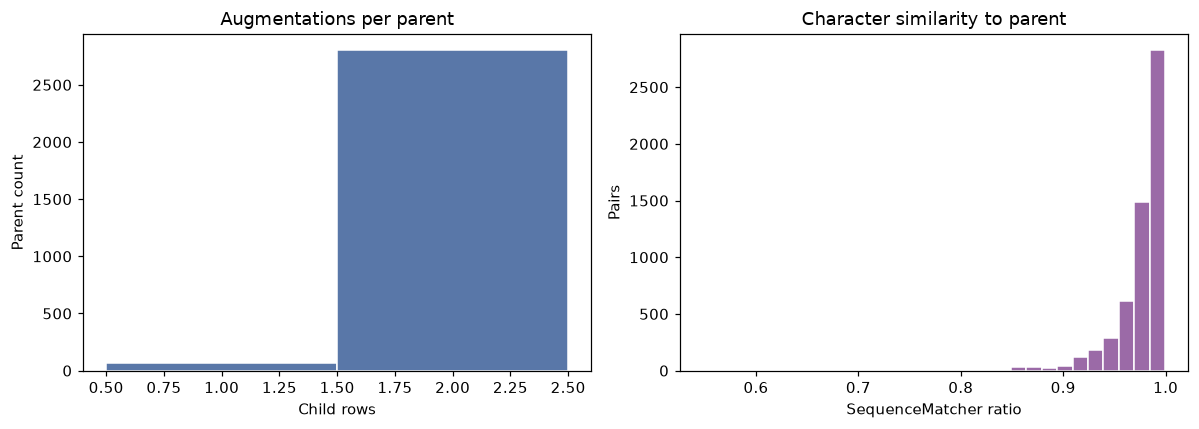

Trong 5,675 cặp, similarity trung vị là 0.984; p10–p90 là 0.947–0.996. Đây là độ giống ký tự giữa các cặp có liên kết, không phải đo ngữ nghĩa hoặc độ chính xác nhãn.

In [7]:
display(augmentation.groupby(['split', 'label'], dropna=False).size().rename('count').to_frame())
parent_counts = augmentation.groupby('parent_id').size().rename('augmentations_per_parent')
aug_keys_all = [normalized_key(t) for t in augmentation['text'] if isinstance(t, str)]; aug_keys_all = [k for k in aug_keys_all if k]
print(f'Rows={len(augmentation):,}; parents={augmentation["parent_id"].nunique():,}; exact duplicate text rows={augmentation["text"].duplicated().sum():,}; normalized duplicate key rows={len(aug_keys_all)-len(set(aug_keys_all)):,}')
display(parent_counts.describe(percentiles=[.25, .5, .75, .95]).to_frame().round(2))
aug_lengths = pd.DataFrame({'words': augmentation['text'].map(lambda t: len(t.split())), 'characters': augmentation['text'].str.len()}); display(aug_lengths.describe(percentiles=[.25, .5, .75, .9, .95, .99]).round(2))
parent_texts = n2_train.set_index('id')['text']
similarity = pd.Series([SequenceMatcher(None, parent, child).ratio() for parent, child in zip(augmentation['parent_id'].map(parent_texts), augmentation['text'])], name='similarity')
assert similarity.notna().all(), 'Missing parent text in similarity pairs'
display(similarity.describe(percentiles=[.1, .25, .5, .75, .9, .95, .99]).to_frame().T.round(4))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(parent_counts, bins=np.arange(.5, parent_counts.max() + 1.5), color='#5977a8', edgecolor='white'); axes[0].set_title('Augmentations per parent'); axes[0].set_xlabel('Child rows'); axes[0].set_ylabel('Parent count')
axes[1].hist(similarity, bins=30, color='#9b6aa7', edgecolor='white'); axes[1].set_title('Character similarity to parent'); axes[1].set_xlabel('SequenceMatcher ratio'); axes[1].set_ylabel('Pairs')
fig.tight_layout(); plt.show()
display(Markdown(f"Trong {len(similarity):,} cặp, similarity trung vị là {similarity.median():.3f}; p10–p90 là {similarity.quantile(.1):.3f}–{similarity.quantile(.9):.3f}. Đây là độ giống ký tự giữa các cặp có liên kết, không phải đo ngữ nghĩa hoặc độ chính xác nhãn."))


## Diễn giải và giới hạn

Các bảng và biểu đồ trước được tính từ parquet khi thực thi notebook. Tỷ lệ TOXIC của N4 train áp dụng cho train, không phải toàn bộ N4; val/test có số liệu riêng và được so sánh với N2.

Khóa chuẩn hóa chỉ tìm một dạng trùng cụ thể, không dò hết near-duplicate ngữ nghĩa. Similarity chỉ tính các cặp augmentation-parent đã liên kết, không rà soát mọi cặp trong corpus. Không có thread ID để kiểm tra leakage theo thread. Test không blind. EDA không chứng minh cải thiện mô hình hoặc chất lượng giữ nhãn của augmentation.
